<a href="https://colab.research.google.com/github/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA/blob/main/notebooks/30_expansion/32_expansion_arima.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 32 · ARIMA del % agropecuario y pronóstico a 2030

**Autor:** Daniel

**Pregunta (sección 11.2 de la ruta):** ¿a qué ritmo crece el uso agropecuario de la Altillanura y hacia dónde va en 2030?

**Entradas:**
- Panel común `datos/comunes/panel_municipio_anio.csv` (Git, cuaderno 60): `agro_ha` y `area_total_ha` por municipio y año, que vienen de las tablas municipales de MapBiomas Colombia, Colección 3.

**Salidas** (en `modulos/expansion/resultados/` y `modulos/expansion/graficas/`):
- `32_arima_pruebas_estacionariedad.csv`, `32_arima_candidatos.csv`, `32_arima_prueba.csv`, `32_arima_validacion.csv`, `32_arima_ajuste_final.csv`, `32_arima_pronostico_2030.csv`.
- `32_identificacion.png`, `32_validacion.png`, `32_diagnostico.png`, `32_pronostico_2030.png`.

**Modelos:**
1. Referencia (benchmark): caminata aleatoria con deriva. El crecimiento futuro es el crecimiento anual promedio del pasado.
2. ARIMA(p, d, q) sobre el % agropecuario anual de la región, con la especificación por defecto de statsmodels (sin constante cuando d ≥ 1).
3. Sensibilidad: ARIMA(0, 2, 1), que supone que el ritmo de crecimiento cambia de forma permanente. Sirve para ver cuánto depende el pronóstico de 2030 de suponer el ritmo histórico o el reciente.

**Estructura** (la misma para todos los modelos del informe, sección 14.2): datos, supuestos, selección, validación, predicción y límites.

## Paso 1. Rutas y librerías
- En **Colab** clona el repo en `/content/Proyecto-ALTILLANURA`.
- En **local** toma como raíz la carpeta del repo (dos niveles arriba del cuaderno).
- `traer(ruta)` baja de DVC un archivo cuando hace falta.

In [1]:
import os, sys, re, glob, subprocess, warnings
EN_COLAB = 'google.colab' in sys.modules
REPO = 'https://github.com/DanielFelipeRuizBermudez/Proyecto-ALTILLANURA.git'

if EN_COLAB:
    RAIZ = '/content/Proyecto-ALTILLANURA'
    if not os.path.exists(RAIZ):
        subprocess.run(['git', 'clone', '-q', REPO, RAIZ], check=True)
else:
    RAIZ = os.path.abspath(os.path.join('..', '..'))

COMUNES = os.path.join(RAIZ, 'datos', 'comunes')
EXPANSION = os.path.join(RAIZ, 'modulos', 'expansion')
CRUDOS = os.path.join(EXPANSION, 'datos', 'mapbiomas_crudos')
RESULTADOS = os.path.join(EXPANSION, 'resultados')
GRAFICAS = os.path.join(EXPANSION, 'graficas')
os.makedirs(RESULTADOS, exist_ok=True)
os.makedirs(GRAFICAS, exist_ok=True)

def traer(ruta):
    if os.path.exists(os.path.join(RAIZ, ruta)):
        return
    if EN_COLAB:
        from google.colab import auth
        auth.authenticate_user()
        subprocess.run([sys.executable, '-m', 'pip', 'install', '-q', 'dvc[gs]'], check=True)
    subprocess.run([sys.executable, '-m', 'dvc', 'pull', '-q', ruta], cwd=RAIZ, check=True)
    print('Bajado de DVC:', ruta)

def coma(valor, decimales=1):
    return f'{valor:,.{decimales}f}'.replace(',', '_').replace('.', ',').replace('_', '.')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.arima.model import ARIMA
from statsmodels.tsa.stattools import acf, pacf, adfuller, kpss
from statsmodels.stats.diagnostic import acorr_ljungbox
from statsmodels.stats.stattools import jarque_bera

ALFA = 0.05
FIN_ENTRENAMIENTO = 2018
ANIO_PRONOSTICO = 2030
MAXIMO_D = 2
MAXIMO_P = 3
MAXIMO_Q = 3
REZAGOS_LJUNG_BOX = [5, 10]
MODULO_MINIMO = 1.01
ORDEN_SENSIBILIDAD = (0, 2, 1)
CAMINATA = 'Caminata con deriva'

print('Raíz del repo:', RAIZ)

Raíz del repo: c:\Users\mipip\Downloads\altillanura_proyecto_\altillanura_proyecto


## 1. Datos
El % agropecuario regional de cada año es el área de la "Zona agrícola y ganadera" (nivel 1 de MapBiomas) de los siete municipios sobre su área total. Se toma del panel común (`agro_ha` y `area_total_ha`), así que es la misma serie que usan los demás cuadernos; es la misma definición del cuaderno 30. Solo entran los años con dato para los siete municipios.

- **Entrenamiento:** 1985–2018 (34 años).
- **Prueba:** 2019–2024 (6 años), que el modelo no ve al ajustarse.

In [2]:
traer('datos/comunes/panel_municipio_anio.csv')
panel = pd.read_csv(os.path.join(COMUNES, 'panel_municipio_anio.csv'), dtype={'mpio_cdpmp': str})
completos = panel.dropna(subset=['agro_ha', 'area_total_ha']).groupby('anio')['mpio_cdpmp'].nunique()
anios_completos = completos[completos == 7].index
region = (panel[panel['anio'].isin(anios_completos)].groupby('anio')[['agro_ha', 'area_total_ha']].sum())
region['agro_pct'] = region['agro_ha'] / region['area_total_ha'] * 100
serie = region['agro_pct']
ANIOS = serie.index.to_numpy()
AREA_TOTAL_HA = float(region['area_total_ha'].iloc[-1])

entrena = serie[serie.index <= FIN_ENTRENAMIENTO]
prueba = serie[serie.index > FIN_ENTRENAMIENTO]
H_PRUEBA = len(prueba)

print(f'Serie: {ANIOS.min()}–{ANIOS.max()} ({len(serie)} años) | entrenamiento: {len(entrena)} | prueba: {H_PRUEBA}')
print(f'% agropecuario: {ANIOS.min()}: {serie.iloc[0]:.2f} % | {FIN_ENTRENAMIENTO}: {entrena.iloc[-1]:.2f} % | {ANIOS.max()}: {serie.iloc[-1]:.2f} %')
print(f'Crecimiento anual promedio 1985–{FIN_ENTRENAMIENTO}: {np.diff(entrena).mean():.3f} puntos porcentuales')

Serie: 1985–2024 (40 años) | entrenamiento: 34 | prueba: 6
% agropecuario: 1985: 3.89 % | 2018: 11.03 % | 2024: 12.87 %
Crecimiento anual promedio 1985–2018: 0.216 puntos porcentuales


## 2. Supuestos: estacionariedad e identificación
ARIMA necesita una serie estacionaria después de diferenciarla *d* veces. Se prueban d = 0, 1 y 2 sobre el entrenamiento con dos pruebas que se complementan:
- **ADF**: la hipótesis nula es que hay raíz unitaria (no estacionaria). Se rechaza con p < 0,05.
- **KPSS**: la hipótesis nula es que la serie es estacionaria. No se rechaza con p > 0,05.

Se toma la menor *d* en que las dos coinciden. Si no coinciden, se toma la mayor, salvo que muestre señales de sobrediferenciación (autocorrelación de rezago 1 menor que −0,5 o más varianza que con la *d* menor).

La figura muestra la serie original, la serie diferenciada y la ACF y PACF de la serie diferenciada, que orientan los órdenes *p* y *q*.

 d  adf_p  kpss_p  acf_rezago_1  desviacion
 0 0.9989  0.0100        0.8887      1.9494
 1 0.3930  0.0971        0.2990      0.1281
 2 0.0000  0.1000       -0.4575      0.1412

d elegida: 1 (ADF y KPSS no coinciden; con d = 2 hay señales de sobrediferenciación)


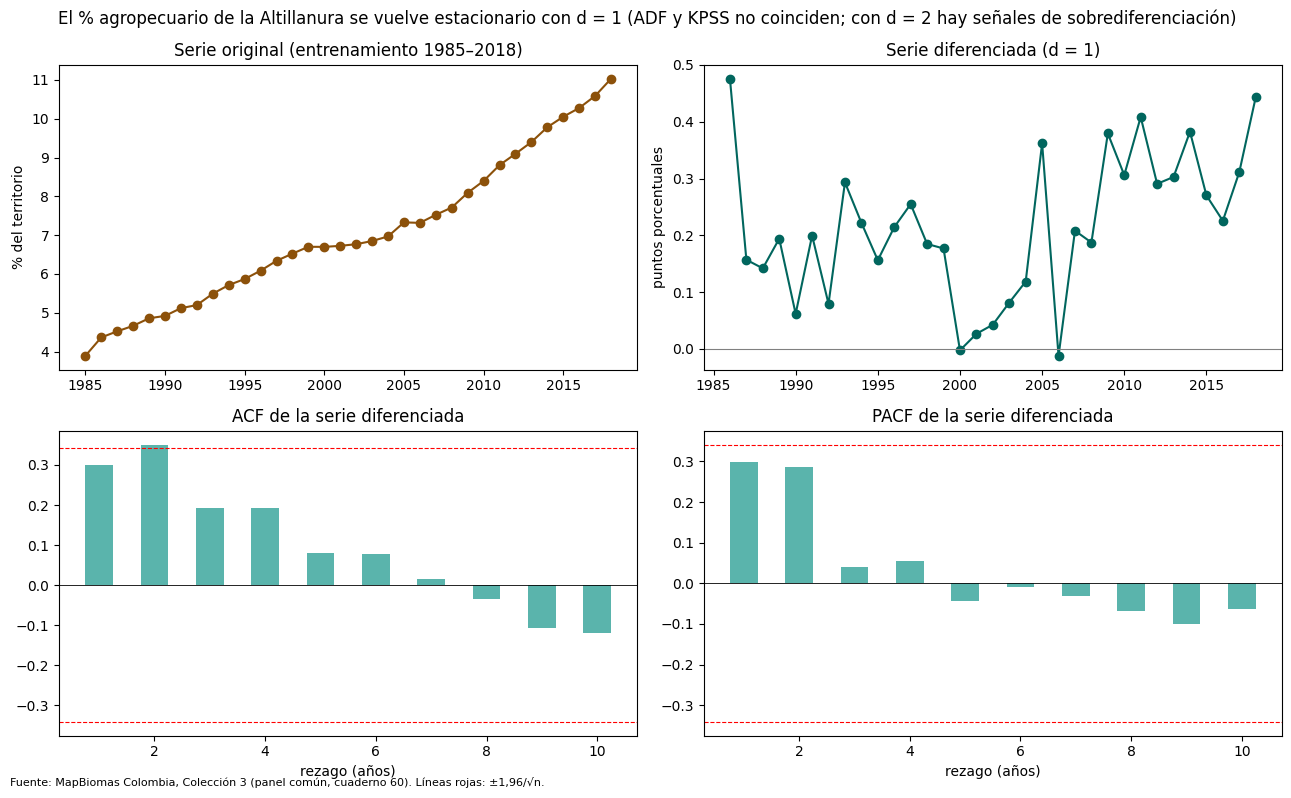

In [3]:
def sin_avisos(funcion, *args, **kwargs):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return funcion(*args, **kwargs)

y_e = entrena.to_numpy()
filas = []
for d in range(MAXIMO_D + 1):
    x = np.diff(y_e, n=d)
    adf = sin_avisos(adfuller, x, regression='c', autolag='AIC')
    prueba_kpss = sin_avisos(kpss, x, regression='c', nlags='auto')
    filas.append({'d': d, 'adf_p': adf[1], 'kpss_p': prueba_kpss[1],
                  'acf_rezago_1': acf(x, nlags=1, fft=False)[1], 'desviacion': x.std(ddof=1)})
pruebas = pd.DataFrame(filas)

adf_ok = pruebas.loc[pruebas['adf_p'] < ALFA, 'd']
kpss_ok = pruebas.loc[pruebas['kpss_p'] > ALFA, 'd']
if adf_ok.empty and kpss_ok.empty:
    D = int(pruebas.loc[pruebas['desviacion'].idxmin(), 'd'])
    razon_d = 'ninguna prueba indica estacionariedad; se usa la d de menor desviación'
elif adf_ok.empty or kpss_ok.empty:
    D = int((kpss_ok if adf_ok.empty else adf_ok).min())
    razon_d = f'solo {"KPSS" if adf_ok.empty else "ADF"} indica estacionariedad'
elif adf_ok.min() == kpss_ok.min():
    D = int(adf_ok.min())
    razon_d = 'ADF y KPSS coinciden'
else:
    menor, mayor = sorted((int(adf_ok.min()), int(kpss_ok.min())))
    t = pruebas.set_index('d')
    sobre = t.loc[mayor, 'acf_rezago_1'] < -0.5 or t.loc[mayor, 'desviacion'] > t.loc[menor, 'desviacion']
    D = menor if sobre else mayor
    razon_d = f'ADF y KPSS no coinciden; con d = {mayor} {"hay" if sobre else "no hay"} señales de sobrediferenciación'

pruebas.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_pruebas_estacionariedad.csv'), index=False)
print(pruebas.round(4).to_string(index=False))
print(f'\nd elegida: {D} ({razon_d})')

dif = np.diff(y_e, n=D)
rezagos = min(10, len(dif) // 2 - 1)
banda = 1.96 / np.sqrt(len(dif))
fig, axes = plt.subplots(2, 2, figsize=(13, 8))
axes[0, 0].plot(entrena.index, y_e, marker='o', color='#8c510a')
axes[0, 0].set_title('Serie original (entrenamiento 1985–2018)')
axes[0, 0].set_ylabel('% del territorio')
axes[0, 1].plot(entrena.index[D:], dif, marker='o', color='#01665e')
axes[0, 1].axhline(0, color='grey', linewidth=0.8)
axes[0, 1].set_title(f'Serie diferenciada (d = {D})')
axes[0, 1].set_ylabel('puntos porcentuales' if D == 1 else f'diferencia de orden {D}')
for ax, valores, nombre in ((axes[1, 0], acf(dif, nlags=rezagos, fft=False), 'ACF'),
                             (axes[1, 1], pacf(dif, nlags=rezagos, method='ywm'), 'PACF')):
    ax.bar(range(1, rezagos + 1), valores[1:rezagos + 1], color='#5ab4ac', width=0.5)
    ax.axhline(banda, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(-banda, color='red', linestyle='--', linewidth=0.8)
    ax.axhline(0, color='black', linewidth=0.6)
    ax.set_title(f'{nombre} de la serie diferenciada')
    ax.set_xlabel('rezago (años)')
fig.suptitle(f'El % agropecuario de la Altillanura se vuelve estacionario con d = {D} ({razon_d})', fontsize=12)
fig.text(0.01, 0.01, 'Fuente: MapBiomas Colombia, Colección 3 (panel común, cuaderno 60). Líneas rojas: ±1,96/√n.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_identificacion.png'), dpi=150, bbox_inches='tight')
plt.show()

## 3. Selección del modelo
Se ajustan todos los ARIMA(p, D, q) con p y q entre 0 y 3 sobre el entrenamiento y se ordenan por **AICc**. Para que un modelo sea apto debe cumplir:
- que el ajuste converja;
- raíces AR y MA fuera del círculo unitario (módulo > 1,01: estacionario e invertible);
- coeficientes significativos (p < 0,05);
- residuos sin autocorrelación (Ljung-Box en los rezagos 5 y 10, p > 0,05).

Se elige el de menor AICc entre los aptos; si ninguno es apto, el de menor AICc.

In [4]:
def ajustar(y, orden):
    with warnings.catch_warnings():
        warnings.simplefilter('ignore')
        return ARIMA(np.asarray(y, dtype=float), order=orden).fit()

def modulos_raices(res):
    nombres = list(res.model.param_names)
    params = np.asarray(res.params, dtype=float)
    ar = [v for n, v in zip(nombres, params) if n.startswith('ar.')]
    ma = [v for n, v in zip(nombres, params) if n.startswith('ma.')]
    modulos = [abs(r) for r in np.roots(np.r_[-np.array(ar)[::-1], 1.0])] if ar else []
    modulos += [abs(r) for r in np.roots(np.r_[np.array(ma)[::-1], 1.0])] if ma else []
    return modulos

def raices_ok(res):
    return all(m > MODULO_MINIMO for m in modulos_raices(res))

def ljung_box(res, d, k):
    residuos = np.asarray(res.resid)[d:]
    tabla = acorr_ljungbox(residuos, lags=REZAGOS_LJUNG_BOX, model_df=k)
    return float(np.min(tabla['lb_pvalue'].to_numpy()))

filas, ajustes = [], {}
for p in range(MAXIMO_P + 1):
    for q in range(MAXIMO_Q + 1):
        try:
            res = ajustar(y_e, (p, D, q))
        except Exception as error:
            print(f'ARIMA({p},{D},{q}) no se pudo ajustar: {error}')
            continue
        nombres = list(res.model.param_names)
        p_valores = np.asarray(res.pvalues, dtype=float)
        sin_sigma = [pv for n, pv in zip(nombres, p_valores) if n != 'sigma2']
        lb_p = ljung_box(res, D, p + q)
        ajustes[(p, q)] = res
        filas.append({'modelo': f'ARIMA({p},{D},{q})', 'p': p, 'd': D, 'q': q, 'aicc': res.aicc,
                      'converge': bool((getattr(res, 'mle_retvals', None) or {}).get('converged', True)),
                      'raices_ok': raices_ok(res),
                      'coef_significativos': bool(all(pv < ALFA for pv in sin_sigma)) if sin_sigma else True,
                      'ljung_box_p': lb_p, 'ljung_box_ok': lb_p > ALFA})
candidatos = pd.DataFrame(filas).sort_values('aicc').reset_index(drop=True)
candidatos['apto'] = candidatos[['converge', 'raices_ok', 'coef_significativos', 'ljung_box_ok']].all(axis=1)
aptos = candidatos[candidatos['apto']]
elegido = aptos.iloc[0] if not aptos.empty else candidatos.iloc[0]
ORDEN = (int(elegido['p']), D, int(elegido['q']))
NOMBRE = elegido['modelo']
razon_modelo = 'el de menor AICc entre los aptos' if not aptos.empty else 'ningún modelo es apto; se deja el de menor AICc'

candidatos.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_candidatos.csv'), index=False)
print(candidatos.head(10).round(3).to_string(index=False))
print(f'\nModelo elegido: {NOMBRE} ({razon_modelo})')

      modelo  p  d  q    aicc  converge  raices_ok  coef_significativos  ljung_box_p  ljung_box_ok  apto
ARIMA(1,1,1)  1  1  1 -37.750      True       True                 True        0.763          True  True
ARIMA(2,1,0)  2  1  0 -37.643      True       True                 True        0.489          True  True
ARIMA(2,1,1)  2  1  1 -35.535      True       True                False        0.557          True False
ARIMA(1,1,2)  1  1  2 -35.323      True       True                False        0.582          True False
ARIMA(3,1,0)  3  1  0 -35.297      True       True                False        0.423          True False
ARIMA(3,1,1)  3  1  1 -33.830     False      False                False        0.268          True False
ARIMA(1,1,3)  1  1  3 -33.367      True      False                False        0.355          True False
ARIMA(2,1,2)  2  1  2 -33.094      True       True                False        0.280          True False
ARIMA(1,1,0)  1  1  0 -31.742      True       True     

## 4. Validación con 2019–2024
Con los datos hasta 2018 se pronostican 2019–2024 (1 a 6 años adelante) con el ARIMA elegido, con la caminata con deriva y con el ARIMA(0, 2, 1) de sensibilidad, y se comparan con lo observado.

- **MAE** y **RMSE**: error medio absoluto y raíz del error cuadrático medio, en puntos porcentuales.
- **MAPE**: error porcentual absoluto medio, en % del valor observado.
- **MASE**: MAE dividido entre el error medio de la caminata ingenua (sin deriva) de un paso en el entrenamiento. Menos de 1 es mejor que esa referencia.
- **MAE relativo a la caminata con deriva**: MAE del modelo sobre MAE de la caminata con deriva. Menos de 1 significa que el modelo le gana a la referencia.
- **Cobertura**: % de años de prueba dentro del intervalo del 95 %.

             modelo  mae_pp  rmse_pp  mape_pct  mase  cobertura_95_pct  mae_relativo_caminata
       ARIMA(1,1,1)   0.172    0.184     1.453 0.791             100.0                  0.660
       ARIMA(0,2,1)   0.233    0.239     1.947 1.072             100.0                  0.895
Caminata con deriva   0.260    0.323     2.095 1.198             100.0                  1.000

Mejor en la prueba 2019–2024: ARIMA(1,1,1)


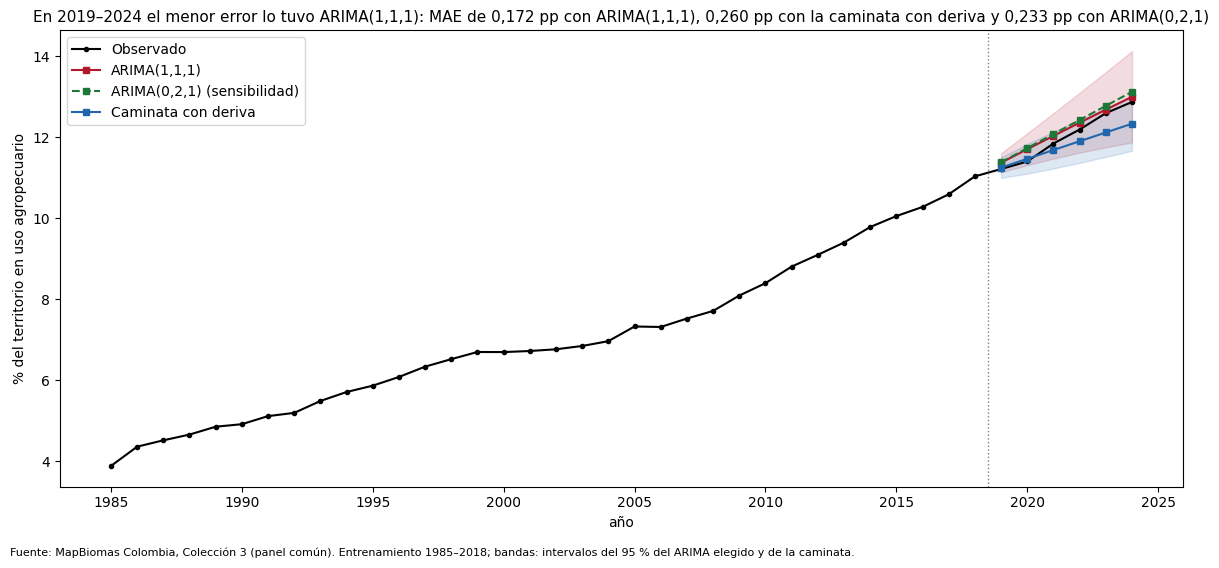

In [5]:
def caminata_con_deriva(y, pasos):
    y = np.asarray(y, dtype=float)
    cambios = np.diff(y)
    deriva = cambios.mean()
    sigma = np.sqrt(np.sum((cambios - deriva) ** 2) / (len(cambios) - 1))
    h = np.arange(1, pasos + 1)
    media = y[-1] + h * deriva
    se = sigma * np.sqrt(h * (1 + h / len(cambios)))
    z = stats.norm.ppf(1 - ALFA / 2)
    return pd.DataFrame({'mean': media, 'mean_ci_lower': media - z * se, 'mean_ci_upper': media + z * se})

def pronostico_arima(res, pasos):
    marco = res.get_forecast(steps=pasos).summary_frame(alpha=ALFA)
    return pd.DataFrame({c: np.asarray(marco[c], dtype=float) for c in ('mean', 'mean_ci_lower', 'mean_ci_upper')})

res_entrena = ajustes[(ORDEN[0], ORDEN[2])]
escala_mase = np.mean(np.abs(np.diff(y_e)))
observado = prueba.to_numpy()

ORDENES = {NOMBRE: ORDEN}
SENSIBILIDAD = 'ARIMA({},{},{})'.format(*ORDEN_SENSIBILIDAD)
if ORDEN_SENSIBILIDAD != ORDEN:
    ORDENES[SENSIBILIDAD] = ORDEN_SENSIBILIDAD
entrenados = {nombre: (res_entrena if orden == ORDEN else ajustar(y_e, orden)) for nombre, orden in ORDENES.items()}
marcos_prueba = {nombre: pronostico_arima(res, H_PRUEBA) for nombre, res in entrenados.items()}
marcos_prueba[CAMINATA] = caminata_con_deriva(y_e, H_PRUEBA)

tablas, metricas = [], []
for nombre, marco in marcos_prueba.items():
    error = marco['mean'].to_numpy() - observado
    dentro = (observado >= marco['mean_ci_lower']) & (observado <= marco['mean_ci_upper'])
    tablas.append(pd.DataFrame({'modelo': nombre, 'anio': prueba.index, 'horizonte': np.arange(1, H_PRUEBA + 1),
                                'observado_pct': observado, 'pronostico_pct': marco['mean'],
                                'inferior_95': marco['mean_ci_lower'], 'superior_95': marco['mean_ci_upper'], 'error_pp': error}))
    metricas.append({'modelo': nombre, 'mae_pp': np.mean(np.abs(error)), 'rmse_pp': np.sqrt(np.mean(error ** 2)),
                     'mape_pct': np.mean(np.abs(error) / np.abs(observado)) * 100,
                     'mase': np.mean(np.abs(error)) / escala_mase, 'cobertura_95_pct': dentro.mean() * 100})
detalle = pd.concat(tablas, ignore_index=True)
metricas = pd.DataFrame(metricas)
metricas['mae_relativo_caminata'] = metricas['mae_pp'] / metricas.loc[metricas['modelo'] == CAMINATA, 'mae_pp'].iloc[0]

detalle.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_prueba.csv'), index=False)
metricas.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_validacion.csv'), index=False)
print(metricas.round(3).to_string(index=False))
GANA = metricas.loc[metricas['mae_pp'].idxmin(), 'modelo']
print(f'\nMejor en la prueba 2019–2024: {GANA}')

colores = {NOMBRE: '#b2182b', CAMINATA: '#2166ac', SENSIBILIDAD: '#1b7837'}
lineas = {NOMBRE: '-', CAMINATA: '-', SENSIBILIDAD: '--'}
fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(serie.index, serie.values, color='black', marker='o', markersize=3, label='Observado')
ax.axvline(FIN_ENTRENAMIENTO + 0.5, color='grey', linestyle=':', linewidth=1)
for nombre, grupo in detalle.groupby('modelo', sort=False):
    etiqueta = f'{nombre} (sensibilidad)' if nombre == SENSIBILIDAD else nombre
    ax.plot(grupo['anio'], grupo['pronostico_pct'], color=colores[nombre], linestyle=lineas[nombre], marker='s', markersize=4, label=etiqueta)
    if nombre != SENSIBILIDAD:
        ax.fill_between(grupo['anio'], grupo['inferior_95'], grupo['superior_95'], color=colores[nombre], alpha=0.15)
ax.set_ylabel('% del territorio en uso agropecuario')
ax.set_xlabel('año')
ax.legend()
mae = metricas.set_index('modelo')['mae_pp']
ax.set_title(f'En 2019–2024 el menor error lo tuvo {GANA}: MAE de {coma(mae[NOMBRE], 3)} pp con {NOMBRE}, '
             f'{coma(mae[CAMINATA], 3)} pp con la caminata con deriva'
             + (f' y {coma(mae[SENSIBILIDAD], 3)} pp con {SENSIBILIDAD}' if SENSIBILIDAD in mae.index else ''), fontsize=11)
fig.text(0.01, -0.02, 'Fuente: MapBiomas Colombia, Colección 3 (panel común). Entrenamiento 1985–2018; bandas: intervalos del 95 % del ARIMA elegido y de la caminata.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_validacion.png'), dpi=150, bbox_inches='tight')
plt.show()

## 5. Predicción a 2030
Los dos ARIMA se vuelven a ajustar con toda la serie (1985–2024) y se les aplican **los mismos criterios de la selección**:
- raíces AR y MA con módulo > 1,01;
- coeficientes significativos (p < 0,05);
- **Ljung-Box** (rezagos 5 y 10): sin autocorrelación si p > 0,05.

Además se revisa la normalidad de los residuos (**Shapiro-Wilk** y **Jarque-Bera**, p > 0,05). Si falla, los intervalos del 95 % son aproximados.

Luego se pronostica 2025–2030 con los tres modelos. Como el pronóstico depende de qué ritmo de crecimiento se suponga, **el resultado de 2030 se da como un rango**: del menor al mayor pronóstico puntual de los tres modelos. El pronóstico se da en % del territorio y en hectáreas (con el área total de 2024).

      modelo        papel                  coeficientes  modulo_minimo_raices  raices_ok  coef_significativos  ljung_box_p_5  ljung_box_p_10  ljung_box_ok  shapiro_p  jarque_bera_p  cumple_criterios
ARIMA(1,1,1)      elegido ar.L1 = 0.992; ma.L1 = -0.703                 1.008      False                 True          0.876           0.987          True      0.193          0.022             False
ARIMA(0,2,1) sensibilidad                ma.L1 = -0.704                 1.420       True                 True          0.779           0.967          True      0.987          0.971              True

Criterio de raíces en el ajuste final: el ajuste final de ARIMA(1,1,1) no cumple el criterio de raíces (módulo mínimo 1,008 ≤ 1,01): la raíz AR queda casi en 1, así que el modelo se comporta casi como uno con d = 2 y extiende el ritmo reciente.


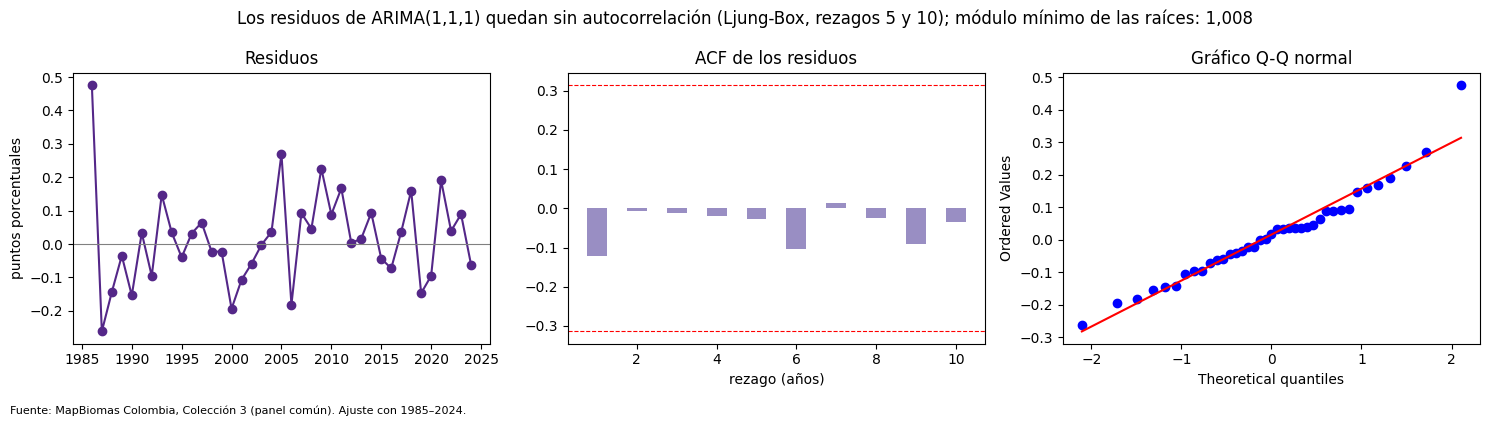

             modelo  anio  agro_pct  inferior_95_pct  superior_95_pct    agro_ha  inferior_95_ha  superior_95_ha
       ARIMA(1,1,1)  2030     14.73            13.72            15.75 1986833.24      1849965.10      2123701.39
       ARIMA(0,2,1)  2030     14.82            13.79            15.85 1998942.49      1859704.14      2138180.84
Caminata con deriva  2030     14.25            13.58            14.91 1921509.39      1832211.09      2010807.68


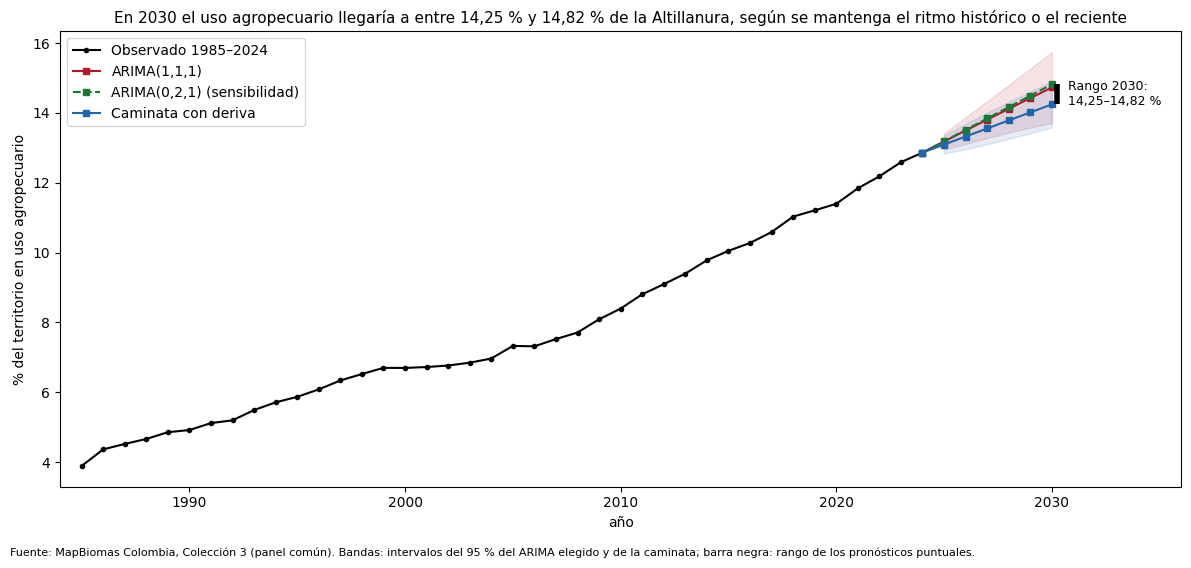

In [6]:
y_total = serie.to_numpy()
finales, filas = {}, []
for nombre, orden in ORDENES.items():
    res = ajustar(y_total, orden)
    finales[nombre] = res
    residuos_m = np.asarray(res.resid)[orden[1]:]
    lb = acorr_ljungbox(residuos_m, lags=REZAGOS_LJUNG_BOX, model_df=orden[0] + orden[2])
    nombres_p = list(res.model.param_names)
    sin_sigma = [pv for n, pv in zip(nombres_p, np.asarray(res.pvalues, dtype=float)) if n != 'sigma2']
    fila = {'modelo': nombre, 'papel': 'elegido' if orden == ORDEN else 'sensibilidad',
            'coeficientes': '; '.join(f'{n} = {v:.3f}' for n, v in zip(nombres_p, np.asarray(res.params, dtype=float)) if n != 'sigma2'),
            'modulo_minimo_raices': min(modulos_raices(res), default=np.nan), 'raices_ok': raices_ok(res),
            'coef_significativos': bool(all(pv < ALFA for pv in sin_sigma)) if sin_sigma else True}
    fila.update({f'ljung_box_p_{r}': float(v) for r, v in zip(REZAGOS_LJUNG_BOX, lb['lb_pvalue'].to_numpy())})
    fila['ljung_box_ok'] = min(fila[f'ljung_box_p_{r}'] for r in REZAGOS_LJUNG_BOX) > ALFA
    fila['shapiro_p'] = float(stats.shapiro(residuos_m)[1])
    fila['jarque_bera_p'] = float(jarque_bera(residuos_m)[1])
    fila['cumple_criterios'] = fila['raices_ok'] and fila['coef_significativos'] and fila['ljung_box_ok']
    filas.append(fila)
ajuste_final = pd.DataFrame(filas)
ajuste_final.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_ajuste_final.csv'), index=False)
print(ajuste_final.round(3).to_string(index=False))

res_final = finales[NOMBRE]
FINAL = ajuste_final.set_index('modelo').loc[NOMBRE]
MODULO_FINAL = FINAL['modulo_minimo_raices']
residuos = np.asarray(res_final.resid)[ORDEN[1]:]
diagnostico = {k: FINAL[k] for k in [f'ljung_box_p_{r}' for r in REZAGOS_LJUNG_BOX] + ['shapiro_p', 'jarque_bera_p']}
if FINAL['raices_ok']:
    AVISO_RAICES = f'el ajuste final de {NOMBRE} cumple el criterio de raíces (módulo mínimo {coma(MODULO_FINAL, 3)} > 1,01)'
else:
    AVISO_RAICES = (f'el ajuste final de {NOMBRE} no cumple el criterio de raíces (módulo mínimo {coma(MODULO_FINAL, 3)} ≤ 1,01): '
                    f'la raíz AR queda casi en 1, así que el modelo se comporta casi como uno con d = 2 y extiende el ritmo reciente')
print(f'\nCriterio de raíces en el ajuste final: {AVISO_RAICES}.')

fig, axes = plt.subplots(1, 3, figsize=(15, 4))
axes[0].plot(serie.index[ORDEN[1]:], residuos, marker='o', color='#542788')
axes[0].axhline(0, color='grey', linewidth=0.8)
axes[0].set_title('Residuos')
axes[0].set_ylabel('puntos porcentuales')
rez = min(10, len(residuos) // 2 - 1)
axes[1].bar(range(1, rez + 1), acf(residuos, nlags=rez, fft=False)[1:], color='#998ec3', width=0.5)
for signo in (1, -1):
    axes[1].axhline(signo * 1.96 / np.sqrt(len(residuos)), color='red', linestyle='--', linewidth=0.8)
axes[1].set_title('ACF de los residuos')
axes[1].set_xlabel('rezago (años)')
stats.probplot(residuos, dist='norm', plot=axes[2])
axes[2].set_title('Gráfico Q-Q normal')
estado = 'sin autocorrelación' if FINAL['ljung_box_ok'] else 'con autocorrelación'
fig.suptitle(f'Los residuos de {NOMBRE} quedan {estado} (Ljung-Box, rezagos 5 y 10); '
             f'módulo mínimo de las raíces: {coma(MODULO_FINAL, 3)}', fontsize=12)
fig.text(0.01, -0.03, 'Fuente: MapBiomas Colombia, Colección 3 (panel común). Ajuste con 1985–2024.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_diagnostico.png'), dpi=150, bbox_inches='tight')
plt.show()

pasos = ANIO_PRONOSTICO - int(ANIOS.max())
futuro = np.arange(ANIOS.max() + 1, ANIO_PRONOSTICO + 1)
marcos_futuro = {nombre: pronostico_arima(res, pasos) for nombre, res in finales.items()}
marcos_futuro[CAMINATA] = caminata_con_deriva(y_total, pasos)
partes = []
for nombre, marco in marcos_futuro.items():
    tabla = pd.DataFrame({'modelo': nombre, 'anio': futuro, 'agro_pct': marco['mean'],
                          'inferior_95_pct': marco['mean_ci_lower'], 'superior_95_pct': marco['mean_ci_upper']})
    for c in ('agro_pct', 'inferior_95_pct', 'superior_95_pct'):
        tabla[c.replace('_pct', '_ha')] = tabla[c] / 100 * AREA_TOTAL_HA
    partes.append(tabla)
pronostico = pd.concat(partes, ignore_index=True)
pronostico.round(4).to_csv(os.path.join(RESULTADOS, '32_arima_pronostico_2030.csv'), index=False)
print(pronostico[pronostico['anio'] == ANIO_PRONOSTICO].round(2).to_string(index=False))

en_2030 = pronostico[pronostico['anio'] == ANIO_PRONOSTICO].set_index('modelo')
RANGO = en_2030['agro_pct'].agg(['min', 'max'])
RANGO_HA = en_2030['agro_ha'].agg(['min', 'max'])
RANGO_IC = (en_2030['inferior_95_pct'].min(), en_2030['superior_95_pct'].max())

fig, ax = plt.subplots(figsize=(12, 5.5))
ax.plot(serie.index, serie.values, color='black', marker='o', markersize=3, label='Observado 1985–2024')
for nombre, grupo in pronostico.groupby('modelo', sort=False):
    etiqueta = f'{nombre} (sensibilidad)' if nombre == SENSIBILIDAD else nombre
    ax.plot(np.r_[ANIOS.max(), grupo['anio']], np.r_[y_total[-1], grupo['agro_pct']], color=colores[nombre],
            linestyle=lineas[nombre], marker='s', markersize=4, label=etiqueta)
    if nombre != SENSIBILIDAD:
        ax.fill_between(grupo['anio'], grupo['inferior_95_pct'], grupo['superior_95_pct'], color=colores[nombre], alpha=0.12)
ax.vlines(ANIO_PRONOSTICO + 0.25, RANGO['min'], RANGO['max'], color='black', linewidth=4)
ax.annotate(f'Rango {ANIO_PRONOSTICO}:\n{coma(RANGO["min"], 2)}–{coma(RANGO["max"], 2)} %', (ANIO_PRONOSTICO + 0.25, RANGO.mean()),
            xytext=(8, 0), textcoords='offset points', va='center', fontsize=9)
ax.set_xlim(ANIOS.min() - 1, ANIO_PRONOSTICO + 6)
ax.set_ylabel('% del territorio en uso agropecuario')
ax.set_xlabel('año')
ax.legend(loc='upper left')
ax.set_title(f'En {ANIO_PRONOSTICO} el uso agropecuario llegaría a entre {coma(RANGO["min"], 2)} % y {coma(RANGO["max"], 2)} % de la Altillanura, '
             f'según se mantenga el ritmo histórico o el reciente', fontsize=11)
fig.text(0.01, -0.02, 'Fuente: MapBiomas Colombia, Colección 3 (panel común). Bandas: intervalos del 95 % del ARIMA elegido y de la caminata; '
         'barra negra: rango de los pronósticos puntuales.', fontsize=8)
plt.tight_layout()
plt.savefig(os.path.join(GRAFICAS, '32_pronostico_2030.png'), dpi=150, bbox_inches='tight')
plt.show()

## 6. Límites
- La serie es corta: 34 años de entrenamiento y una sola ventana de prueba de 6 años, así que las métricas de validación tienen mucha incertidumbre.
- ARIMA solo extrapola la dinámica pasada de la serie. No incluye causas como precios, crédito, vías, políticas o tenencia de la tierra, y no anticipa cambios de régimen.
- El nivel 1 "Zona agrícola y ganadera" incluye el mosaico de agricultura y pastos, así que mezcla cultivos con ganadería.
- Los intervalos del 95 % suponen residuos normales; si Shapiro-Wilk o Jarque-Bera rechazan normalidad, son aproximados.
- Si en el ajuste final el módulo de una raíz AR queda cerca de 1, el ritmo de crecimiento anual es muy persistente: el ARIMA proyecta el ritmo de los últimos años y la caminata con deriva el promedio de toda la serie. Por eso 2030 se reporta como rango y no como un solo valor.
- La validación no decide cuál ritmo se mantendrá: es una sola ventana de 6 años, cae en el periodo en que la expansión se aceleró, y los intervalos de los modelos cubren lo observado.
- Una nueva colección de MapBiomas puede reclasificar años anteriores y mover la serie.

## Resumen para el informe

In [7]:
a = metricas.set_index('modelo')
print(f'Datos: % agropecuario anual de la Altillanura (MapBiomas Col. 3, panel común), {ANIOS.min()}–{ANIOS.max()}; '
      f'pasó de {coma(serie.iloc[0], 2)} % a {coma(serie.iloc[-1], 2)} %.')
print(f'Supuestos: d = {D} ({razon_d}).')
print(f'Selección: {NOMBRE}, {razon_modelo} ({len(candidatos)} candidatos).')
for nombre in a.index:
    print(f'Validación 2019–2024, {nombre}: MAE {coma(a.loc[nombre, "mae_pp"], 3)} pp, MAPE {coma(a.loc[nombre, "mape_pct"], 2)} %, '
          f'MASE {coma(a.loc[nombre, "mase"], 2)}, MAE relativo a la caminata {coma(a.loc[nombre, "mae_relativo_caminata"], 2)}.')
print(f'Ajuste final: {AVISO_RAICES}.')
ritmo_reciente = (serie.iloc[-1] - serie.loc[FIN_ENTRENAMIENTO]) / H_PRUEBA
print(f'Predicción {ANIO_PRONOSTICO}: entre {coma(RANGO["min"], 2)} % y {coma(RANGO["max"], 2)} % del territorio '
      f'(unas {coma(RANGO_HA["min"] / 1e3, 0)} a {coma(RANGO_HA["max"] / 1e3, 0)} mil ha); '
      f'intervalos del 95 % entre {coma(RANGO_IC[0], 2)} % y {coma(RANGO_IC[1], 2)} %.')
for nombre, fila in en_2030.iterrows():
    ritmo = (fila.agro_pct - serie.iloc[-1]) / pasos
    print(f'  {nombre}: {coma(fila.agro_pct, 2)} % (IC 95 %: {coma(fila.inferior_95_pct, 2)}–{coma(fila.superior_95_pct, 2)} %), '
          f'sube {coma(ritmo, 2)} pp por año.')
print(f'Ritmo observado: {coma(np.diff(y_total).mean(), 2)} pp por año en promedio {ANIOS.min()}–{ANIOS.max()} '
      f'y {coma(ritmo_reciente, 2)} pp por año en {FIN_ENTRENAMIENTO}–{ANIOS.max()}.')

Datos: % agropecuario anual de la Altillanura (MapBiomas Col. 3, panel común), 1985–2024; pasó de 3,89 % a 12,87 %.
Supuestos: d = 1 (ADF y KPSS no coinciden; con d = 2 hay señales de sobrediferenciación).
Selección: ARIMA(1,1,1), el de menor AICc entre los aptos (16 candidatos).
Validación 2019–2024, ARIMA(1,1,1): MAE 0,172 pp, MAPE 1,45 %, MASE 0,79, MAE relativo a la caminata 0,66.
Validación 2019–2024, ARIMA(0,2,1): MAE 0,233 pp, MAPE 1,95 %, MASE 1,07, MAE relativo a la caminata 0,89.
Validación 2019–2024, Caminata con deriva: MAE 0,260 pp, MAPE 2,09 %, MASE 1,20, MAE relativo a la caminata 1,00.
Ajuste final: el ajuste final de ARIMA(1,1,1) no cumple el criterio de raíces (módulo mínimo 1,008 ≤ 1,01): la raíz AR queda casi en 1, así que el modelo se comporta casi como uno con d = 2 y extiende el ritmo reciente.
Predicción 2030: entre 14,25 % y 14,82 % del territorio (unas 1.922 a 1.999 mil ha); intervalos del 95 % entre 13,58 % y 15,85 %.
  ARIMA(1,1,1): 14,73 % (IC 95 %: 13,72–1